
# Automated Material Recognition
_Using a trash dataset to build a image based classification model_

---

## Table of Contents
1. [Introduction](#introduction)  
2. [Initial Setup](#initial-setup)  
3. [Data Ingestion](#data-ingestion)  
4. [Exploratorty Data Analysis](#exploritory-data-analaysis)  
5. [Data Cleaning & Preprocessing](#data-cleaning-preprocessing)  
6. [Modelling / Training](#modelling-training)  
7. [Evaluation](#evaluation)  
8. [Conclusion](#conclusion)



## Introduction <a id='introduction'></a>
In this notebook the key objective is to ...


TODOs:

- Look at removing data loaders dependency on the OS library
- Find where the @dataclass directive could be used?
- Standardise and consolidate print statements with display & HTML etc...

## Inital Setup <a id='initial-setup'></a>

In [25]:

# Import libraries
## DataLoader Dependencies
import os
import zipfile
from pathlib import Path
from IPython.display import display, HTML
import pandas as pd
## EDA Dependencies
import seaborn as sns
from matplotlib import pyplot as plt

# Configure Settings


# Define Constants
ZIP_PATH = './AI_Portfolio_Dataset.zip'
EXTRACT_DIR = './'
RANDOM_SEED = 42 

## Data Ingestion <a id='data-ingestion'></a>

I will be using a DataFrame for the in memory storage of the dataset as this allows for:

- **EDA Integration** - Effective leverage of the Pandas library in exploritory data analysis
- **PyTorch Compatibility** - Custom `Dataset` classes can index into DataFrames so simple data loader building
- **Quality Tracking** - Extra columns allow for clean preprocessing without a restructure of core data 

 with the following columns:

| Column Name     | Data Type | Example Value                      | Description                           |
|-----------------|-----------|------------------------------------|---------------------------------------|
| `file_path`     | string    | `path/to/train_cardboard_000.jpg`  | Full file path                        |
| `filename`      | string    | `train_cardboard_000.jpg`          | Original filename                     |
| `split`         | string    | `train`                            | Dataset split (train/test)            |
| `label`         | string    | `cardboard`                        | String label                          |
| `label_encoded` | int       | `0`                                | Integer encoded label (0-4)           |
| `file_size`     | int       | `125340`                           | File size in bytes (optional for EDA) |
| `is_valid`      | bool      | `True`                             | Data quality check flag (optional)    |

In [26]:
# Define Dataset Loader Class for handling dataset extraction and loading
class DatasetLoader:
    """Handles the extraction and loading of the dataset into memory"""

    def __init__(self, zip_path, extract_dir) -> None:
        self._zip_path = Path(zip_path)
        self._extract_dir = Path(extract_dir)
        self.train_df = None
        self.test_df = None
        # Auto extract & create split DFs when instantiated
        self._extract_dataset()
        self._create_dataframes()

    def _extract_dataset(self) -> None:
        """Extract ZIP file if not already extracted"""
        dataset_folder = self._extract_dir / 'dataset'
        
        if not dataset_folder.exists():
            print(f"Extracting {self._zip_path.name}...")
            with zipfile.ZipFile(self._zip_path, 'r') as zip_ref:
                zip_ref.extractall(self._extract_dir)
            print(f"Dataset extracted: {os.path.abspath(self._extract_dir)}")
        else:
            print(f"Dataset already extracted: {os.path.abspath(dataset_folder)}")

    def _create_dataframes(self) -> None:
        """Create the train and test DataFrames after extraction"""

        dataset_folder = self._extract_dir / 'dataset'
        train_data = []
        test_data = []

        files = [p for p in dataset_folder.rglob('*') if p.is_file() and p.suffix.lower() == '.jpg']
        rows = []
        for file in files:
            split, label, idx, = self._parse_filename(file.name)
            rows.append({
                'file_path': str(file),
                'filename': file.name,
                'split': split,
                'label': label,
                'index': idx,
                'file_size': file.stat().st_size,
                'isValid': True
            })

        self.train_df = pd.DataFrame([row for row in rows if row['split'] == 'train'])
        self.test_df = pd.DataFrame([row for row in rows if row['split'] == 'test'])

    @staticmethod
    def _parse_filename(filename: str) -> tuple[str, str, str]:
        """Parse filename to extract split, label, and index"""
        name_without_ext = filename.rsplit('.', 1)[0]
        parts = name_without_ext.split('_')
        return parts[0], parts[1], parts[2]

In [27]:
# Instantiate DatasetLoader (Will extract the dataset and populate split dataframes)
loader = DatasetLoader(ZIP_PATH, EXTRACT_DIR)

# Access both splits DataFrames
train_df = loader.train_df.copy()
test_df = loader.test_df.copy()

# Show some random samples of the training DataFrame
display(train_df.sample(5).reset_index(drop=True))
display(test_df.sample(5).reset_index(drop=True))

# Distinct query the split column to verify correct loading
print("Distinct splits in training DataFrame:", train_df['split'].unique())

Dataset already extracted: /home/morrison-page/CODESPACE/Assignment/Material Recognition/dataset


,file_path,filename,split,label,index,file_size,isValid
0,dataset/train/train_glass_725.jpg,train_glass_725.jpg,train,glass,725,5739,True
1,dataset/train/train_metal_080.jpg,train_metal_080.jpg,train,metal,080,8501,True
2,dataset/train/train_paper_270.jpg,train_paper_270.jpg,train,paper,270,6917,True
3,dataset/train/train_trash_394.jpg,train_trash_394.jpg,train,trash,394,2031,True
4,dataset/train/train_trash_330.jpg,train_trash_330.jpg,train,trash,330,5636,True


,file_path,filename,split,label,index,file_size,isValid
0,dataset/test/test_paper_113.jpg,test_paper_113.jpg,test,paper,113,5949,True
1,dataset/test/test_cardboard_136.jpg,test_cardboard_136.jpg,test,cardboard,136,5020,True
2,dataset/test/test_plastic_017.jpg,test_plastic_017.jpg,test,plastic,017,2749,True
3,dataset/test/test_metal_122.jpg,test_metal_122.jpg,test,metal,122,14182,True
4,dataset/test/test_cardboard_210.jpg,test_cardboard_210.jpg,test,cardboard,210,8443,True


Distinct splits in training DataFrame: ['train']


## Exploritory Data Analaysis <a id='exploritory-data-analaysis'></a>

Firstly I will cover looking at the quality of the data itself, making sure it is unified for example all images are the same size in pixles etc

,Label,Count,Percent
0,glass,999,~25.07%
1,paper,727,~18.24%
2,cardboard,618,~15.51%
3,plastic,591,~14.83%
4,trash,525,~13.17%
5,metal,525,~13.17%


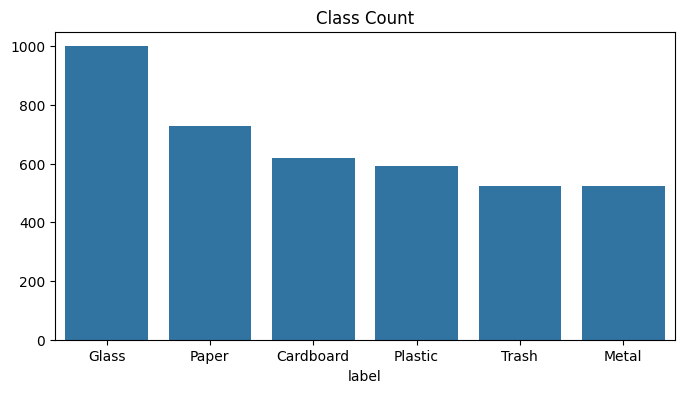

In [28]:
# Class Distribution + Counts & Percents
counts = train_df['label'].value_counts()
percentages = ('~' + (counts / counts.sum() * 100).round(2).astype(str) + '%')
display(pd.concat([counts.rename_axis('Label').reset_index(name='Count'), percentages.rename('Percent').reset_index(drop=True)], axis=1))
plt.figure(figsize=(8,4))
sns.barplot(x=counts.index.str.title(), y=counts.values)
plt.xticks(rotation=0)
plt.title('Class Count')
plt.show()

We can clearly see that the dataset is skewed towards glass and also slightly favours paper, I will need to consider this when augmenting data to ensure an even class distribution 


Image Stats:


,width,height,aspect_ratio
count,3985.000000,3985.000000,3985.000000
mean,357.111669,289.583438,1.232175
std,139.266518,87.217784,0.301581
min,51.000000,100.000000,0.127500
25%,225.000000,217.000000,1.000000
50%,280.000000,262.000000,1.333333
75%,512.000000,384.000000,1.333333
max,512.000000,400.000000,5.020000



Unique Dimension Combinations:
Total unique dimension combinations: 324

Top 10 most common dimensions:


,width,height,count
323,512,384,1737
152,225,225,614
235,275,183,154
211,259,194,139
86,194,259,56
58,183,275,54
273,300,168,49
148,224,224,25
238,276,183,17
106,201,251,17



Are all images uniform? False


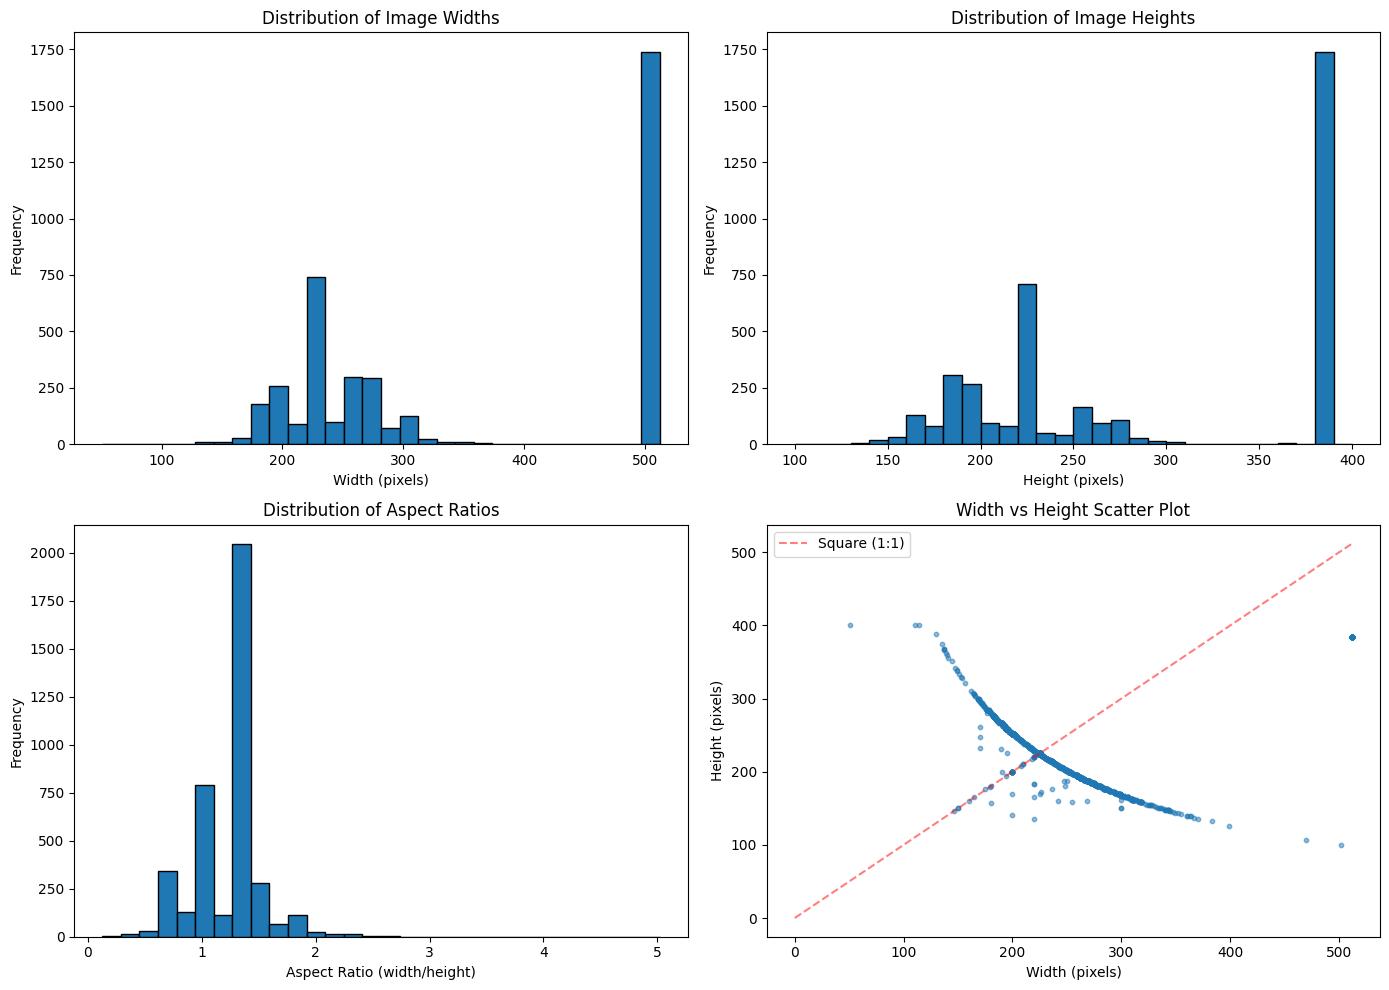

In [29]:
from PIL import Image
import numpy as np

# Image Dimension Analysis
import matplotlib.pyplot as plt

# Load image dimensions for all training images
dimensions = []
for idx, row in train_df.iterrows():
    try:
        with Image.open(row['file_path']) as img:
            width, height = img.size
            dimensions.append({
                'width': width,
                'height': height,
                'aspect_ratio': width / height
            })
    except Exception as e:
        print(f"Error loading {row['filename']}: {e}")

# Create dimensions DataFrame
dims_df = pd.DataFrame(dimensions)

# Basic statistics
print("\nImage Stats:")
display(dims_df.describe())

# Unique dimension combinations
unique_dims = dims_df.groupby(['width', 'height']).size().reset_index(name='count')
print(f"\nUnique Dimension Combinations:")
print(f"Total unique dimension combinations: {len(unique_dims)}")
print("\nTop 10 most common dimensions:")
display(unique_dims.sort_values('count', ascending=False).head(10))

# Check if all images are uniform
is_uniform = len(unique_dims) == 1
print(f"\nAre all images uniform? {is_uniform}")

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Width distribution
axes[0, 0].hist(dims_df['width'], bins=30, edgecolor='black')
axes[0, 0].set_xlabel('Width (pixels)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Image Widths')

# Height distribution
axes[0, 1].hist(dims_df['height'], bins=30, edgecolor='black')
axes[0, 1].set_xlabel('Height (pixels)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Distribution of Image Heights')

# Aspect ratio distribution
axes[1, 0].hist(dims_df['aspect_ratio'], bins=30, edgecolor='black')
axes[1, 0].set_xlabel('Aspect Ratio (width/height)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution of Aspect Ratios')

# Scatter plot of width vs height
axes[1, 1].scatter(dims_df['width'], dims_df['height'], alpha=0.5, s=10)
axes[1, 1].set_xlabel('Width (pixels)')
axes[1, 1].set_ylabel('Height (pixels)')
axes[1, 1].set_title('Width vs Height Scatter Plot')
axes[1, 1].plot([0, dims_df['width'].max()], [0, dims_df['width'].max()], 'r--', alpha=0.5, label='Square (1:1)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

As demonstraited by the graphs the images are all non standard and I could benefit from translating them into a consolidated size before use in training by de/upscaling

,file_size
count,3985.000000
mean,11050.044668
std,7987.174618
min,1186.000000
25%,4572.000000
50%,9445.000000
75%,15099.000000
max,56565.000000


,file_size_kb
count,3985.000000
mean,10.791059
std,7.799975
min,1.158203
25%,4.464844
50%,9.223633
75%,14.745117
max,55.239258


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
cardboard,618.0,11.081565,7.684612,1.631836,4.132324,8.158203,17.591309,34.099609
glass,999.0,7.673691,4.827277,1.358398,3.908203,6.057617,10.757812,33.013672
metal,525.0,12.172511,7.932236,1.765625,5.614258,10.608398,16.869141,49.162109
paper,727.0,17.606234,9.291245,5.305664,11.496582,14.214844,21.136230,55.239258
plastic,591.0,10.663002,5.558917,1.602539,6.336426,9.926758,14.602539,30.706055
trash,525.0,5.706308,4.519881,1.158203,2.863281,3.886719,6.765625,35.428711


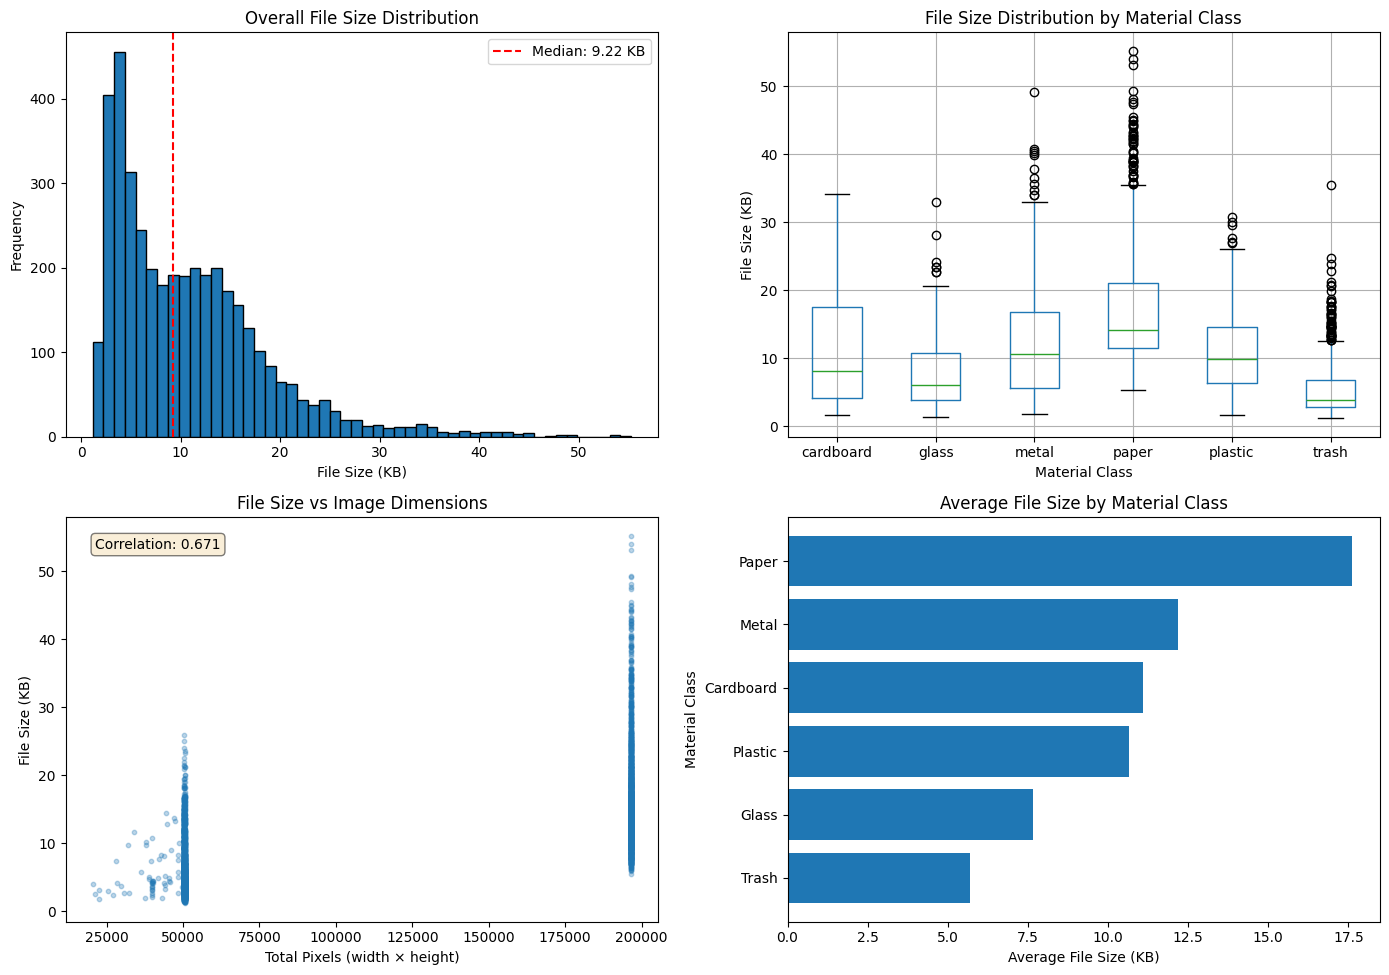

Number of outliers (using IQR method): 116 (2.91%)
Lower bound: -10.96 KB, Upper bound: 30.17 KB


,Mean (KB),Std Dev (KB),Median (KB),Count
label,,,,
paper,17.61,9.29,14.21,727
metal,12.17,7.93,10.61,525
cardboard,11.08,7.68,8.16,618
plastic,10.66,5.56,9.93,591
glass,7.67,4.83,6.06,999
trash,5.71,4.52,3.89,525


,mean,median,std
label,,,
paper,0.182,0.178,0.099
metal,0.106,0.095,0.051
plastic,0.097,0.082,0.055
cardboard,0.097,0.090,0.035
glass,0.090,0.079,0.044
trash,0.079,0.071,0.036


In [30]:
# File Size Analysis

display(HTML("<h2>File Size Statistics (bytes)</h2>"))
display(train_df['file_size'].describe().to_frame())

# Convert to KB for easier interpretation
train_df['file_size_kb'] = train_df['file_size'] / 1024

display(HTML("<h2>File Size Statistics (KB)</h2>"))
display(train_df['file_size_kb'].describe().to_frame())

# File size distribution per class
display(HTML("<h2>File Size Statistics by Material Class (KB)</h2>"))
display(train_df.groupby('label')['file_size_kb'].describe())

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overall file size distribution
axes[0, 0].hist(train_df['file_size_kb'], bins=50, edgecolor='black')
axes[0, 0].set_xlabel('File Size (KB)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Overall File Size Distribution')
axes[0, 0].axvline(train_df['file_size_kb'].median(), color='red', linestyle='--', label=f'Median: {train_df["file_size_kb"].median():.2f} KB')
axes[0, 0].legend()

# File size distribution by class
train_df.boxplot(column='file_size_kb', by='label', ax=axes[0, 1])
axes[0, 1].set_xlabel('Material Class')
axes[0, 1].set_ylabel('File Size (KB)')
axes[0, 1].set_title('File Size Distribution by Material Class')
axes[0, 1].get_figure().suptitle('')  # Remove automatic title

# Merge dimensions data with train_df for correlation analysis
train_df_with_dims = train_df.copy()
train_df_with_dims['width'] = dims_df['width']
train_df_with_dims['height'] = dims_df['height']
train_df_with_dims['pixels'] = dims_df['width'] * dims_df['height']

# Correlation: File size vs total pixels
axes[1, 0].scatter(train_df_with_dims['pixels'], train_df_with_dims['file_size_kb'], alpha=0.3, s=10)
axes[1, 0].set_xlabel('Total Pixels (width × height)')
axes[1, 0].set_ylabel('File Size (KB)')
axes[1, 0].set_title('File Size vs Image Dimensions')

# Calculate correlation
correlation = train_df_with_dims[['pixels', 'file_size_kb']].corr().iloc[0, 1]
axes[1, 0].text(0.05, 0.95, f'Correlation: {correlation:.3f}', 
                transform=axes[1, 0].transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Average file size by material class
avg_size_by_class = train_df.groupby('label')['file_size_kb'].mean().sort_values()
axes[1, 1].barh(avg_size_by_class.index.str.title(), avg_size_by_class.values)
axes[1, 1].set_xlabel('Average File Size (KB)')
axes[1, 1].set_ylabel('Material Class')
axes[1, 1].set_title('Average File Size by Material Class')

plt.tight_layout()
plt.show()

# Identify unusual files
display(HTML("<h2>Unusual File Sizes</h2>"))
q1 = train_df['file_size_kb'].quantile(0.25)
q3 = train_df['file_size_kb'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = train_df[(train_df['file_size_kb'] < lower_bound) | (train_df['file_size_kb'] > upper_bound)]
print(f"Number of outliers (using IQR method): {len(outliers)} ({len(outliers)/len(train_df)*100:.2f}%)")
print(f"Lower bound: {lower_bound:.2f} KB, Upper bound: {upper_bound:.2f} KB")

# Statistical test: Check if file size differs significantly across classes
display(HTML("<h2>File Size Pattern Analysis by Material</h2>"))
compression_analysis = train_df.groupby('label').agg({
    'file_size_kb': ['mean', 'std', 'median'],
    'filename': 'count'
}).round(2)
compression_analysis.columns = ['Mean (KB)', 'Std Dev (KB)', 'Median (KB)', 'Count']
display(compression_analysis.sort_values('Mean (KB)', ascending=False))

# Calculate compression ratio (file size per pixel)
train_df_with_dims['bytes_per_pixel'] = train_df['file_size'] / train_df_with_dims['pixels']
display(HTML("<h2>Compression Ratio Analysis (Bytes per Pixel)</h2>"))
compression_by_class = train_df_with_dims.groupby('label')['bytes_per_pixel'].agg(['mean', 'median', 'std']).round(3)
display(compression_by_class.sort_values('mean', ascending=False))

Here should be an important conclusion about the findings of my file size research!

In [31]:
# Image Quality Checks
from PIL import Image
import numpy as np

display(HTML("<h1>Image Quality Analysis</h1>"))

# Initialize tracking variables
corrupted_images = []
dimension_issues = []
channel_issues = []
greyscale_as_rgb = []
image_modes = {}

# Define thresholds for dimension checks
MIN_DIM = 50  # Minimum reasonable dimension
MAX_DIM = 5000  # Maximum reasonable dimension

for idx, row in train_df.iterrows():
    try:
        with Image.open(row['file_path']) as img:
            width, height = img.size
            mode = img.mode
            
            # Track image modes
            image_modes[mode] = image_modes.get(mode, 0) + 1
            
            # Check for dimension issues
            if width < MIN_DIM or height < MIN_DIM or width > MAX_DIM or height > MAX_DIM:
                dimension_issues.append({
                    'filename': row['filename'],
                    'width': width,
                    'height': height,
                    'issue': 'Too small' if (width < MIN_DIM or height < MIN_DIM) else 'Too large'
                })
            
            # Check channel/mode issues
            if mode not in ['RGB', 'L']:  # L is greyscale
                channel_issues.append({
                    'filename': row['filename'],
                    'mode': mode,
                    'size': (width, height)
                })
            
            # Check for greyscale images saved as RGB
            if mode == 'RGB':
                img_array = np.array(img)
                # Check if all three channels are identical (greyscale masquerading as RGB)
                if img_array.shape[2] == 3:
                    r, g, b = img_array[:,:,0], img_array[:,:,1], img_array[:,:,2]
                    if np.array_equal(r, g) and np.array_equal(g, b):
                        greyscale_as_rgb.append({
                            'filename': row['filename'],
                            'size': (width, height)
                        })
                        
    except Exception as e:
        corrupted_images.append({
            'filename': row['filename'],
            'error': str(e)
        })

# Print Results
display(HTML("<h2>Image Mode Distribution</h2>"))
for mode, count in sorted(image_modes.items(), key=lambda x: x[1], reverse=True):
    percentage = (count / len(train_df)) * 100
    print(f"{mode}: {count} images ({percentage:.2f}%)")

display(HTML("<h2>Corrupted/Unreadable Images</h2>"))
print(f"Total corrupted images: {len(corrupted_images)}")
if corrupted_images:
    corrupted_df = pd.DataFrame(corrupted_images)
    display(corrupted_df)
else:
    print("No corrupted images found!")

# Dimension Issues
display(HTML("<h2>Dimension Issues</h2>"))
print(f"Total images with dimension issues: {len(dimension_issues)}")
print(f"(Thresholds: MIN={MIN_DIM}px, MAX={MAX_DIM}px)")
if dimension_issues:
    dim_issues_df = pd.DataFrame(dimension_issues)
    print("\nBy issue type:")
    display(dim_issues_df.groupby('issue').size())
    print("\nSample of problematic images:")
    display(dim_issues_df.head(10))
else:
    print("No dimension issues found!")

# Channel/Mode Issues
display(HTML("<h2>Chanel/Mode Issues</h2>"))
print(f"Total images with unexpected modes: {len(channel_issues)}")
if channel_issues:
    channel_df = pd.DataFrame(channel_issues)
    display(channel_df)
else:
    print("All images are in expected modes (RGB or L)!")

# Greyscale Issues
display(HTML("<h2>Greyscale Images Saved as RGB</h2>"))
print(f"Total greyscale-as-RGB images: {len(greyscale_as_rgb)}")
if greyscale_as_rgb:
    percentage = (len(greyscale_as_rgb) / len(train_df)) * 100
    print(f"Percentage: {percentage:.2f}%")
    
    # Show distribution by material class
    greyscale_files = [item['filename'] for item in greyscale_as_rgb]
    greyscale_in_df = train_df[train_df['filename'].isin(greyscale_files)]
    
    print("\nDistribution by material class:")
    display(greyscale_in_df['label'].value_counts().to_frame(name='Count'))
    
    print("\nSample greyscale-as-RGB images:")
    display(pd.DataFrame(greyscale_as_rgb).head(10))
else:
    print("No greyscale images masquerading as RGB found!")

# Summary Visualisation
display(HTML("<h2>Overall Quality Summary</h2>"))
quality_summary = {
    'Total Images': len(train_df),
    'Corrupted': len(corrupted_images),
    'Dimension Issues': len(dimension_issues),
    'Channel Issues': len(channel_issues),
    'Greyscale as RGB': len(greyscale_as_rgb),
    'Healthy Images': len(train_df) - len(corrupted_images) - len(dimension_issues) - len(channel_issues)
}

summary_df = pd.DataFrame(list(quality_summary.items()), columns=['Category', 'Count'])
summary_df['Percentage'] = (summary_df['Count'] / len(train_df) * 100).round(2)
display(summary_df.style.hide(axis='index'))

# Flag problematic images in the DataFrame
if corrupted_images or dimension_issues or channel_issues:
    problematic_files = (
        [item['filename'] for item in corrupted_images] +
        [item['filename'] for item in dimension_issues] +
        [item['filename'] for item in channel_issues] +
        [item['filename'] for item in greyscale_as_rgb]
    )
    train_df.loc[train_df['filename'].isin(problematic_files), 'isValid'] = False
    print(f"\nMarked {len(problematic_files)} problematic images with isValid=False")

RGB: 3973 images (99.70%)
P: 12 images (0.30%)


Total corrupted images: 0
No corrupted images found!


Total images with dimension issues: 0
(Thresholds: MIN=50px, MAX=5000px)
No dimension issues found!


Total images with unexpected modes: 12


,filename,mode,size
0,train_trash_093.jpg,P,"(225, 225)"
1,train_glass_415.jpg,P,"(225, 225)"
2,train_trash_199.jpg,P,"(225, 225)"
3,train_trash_076.jpg,P,"(198, 254)"
4,train_paper_460.jpg,P,"(190, 200)"
5,train_trash_227.jpg,P,"(225, 225)"
6,train_trash_185.jpg,P,"(225, 225)"
7,train_trash_458.jpg,P,"(225, 225)"
8,train_trash_078.jpg,P,"(225, 225)"
9,train_trash_308.jpg,P,"(224, 224)"


Total greyscale-as-RGB images: 104
Percentage: 2.61%

Distribution by material class:


,Count
label,
glass,42
paper,30
trash,16
metal,13
plastic,3



Sample greyscale-as-RGB images:


,filename,size
0,train_glass_913.jpg,"(225, 225)"
1,train_glass_167.jpg,"(225, 225)"
2,train_glass_921.jpg,"(225, 225)"
3,train_glass_835.jpg,"(176, 286)"
4,train_paper_342.jpg,"(225, 225)"
5,train_plastic_344.jpg,"(225, 225)"
6,train_glass_272.jpg,"(225, 225)"
7,train_glass_075.jpg,"(225, 225)"
8,train_glass_331.jpg,"(225, 225)"
9,train_glass_948.jpg,"(220, 229)"


Category,Count,Percentage
Total Images,3985,100.000000
Corrupted,0,0.000000
Dimension Issues,0,0.000000
Channel Issues,12,0.300000
Greyscale as RGB,104,2.610000
Healthy Images,3973,99.700000



Marked 116 problematic images with isValid=False


Looking at the quality summary I can see that the images that use P rather than RGB is negligable so will just drop them in preprocessing.

As for the Greyscale images stored in RGB format, they will work in the planned architecture however I will need to make sure their class distribution isn't skewed either by using augmentation or dropping some of the data to avoid the model compensating towards glass (as that is the most represented class by greyscale images) 

In [32]:
# Look for exact duplicate images
import hashlib

# Function to compute SHA256 hash of an image file
def compute_sha256(file_path: str) -> str | None:
    sha256_hash = hashlib.sha256()
    try:
        with open(file_path, "rb") as f:
            # Read file in chunks to avoid memory issues with large files
            for byte_block in iter(lambda: f.read(4096), b""):
                sha256_hash.update(byte_block)
        return sha256_hash.hexdigest()
    except Exception as e:
        print(f"Error computing hash for {file_path}: {e}")
        return None

# Compute SHA256 hashes for all images in the training DataFrame
train_df['sha256'] = train_df['file_path'].apply(compute_sha256)

# Count occurrences of each hash
hash_counts = train_df['sha256'].value_counts()

# Filter hashes with more than 1 occurrence
duplicate_hashes = hash_counts[hash_counts > 1]

# Print duplicate hashes and their occurrences
if not duplicate_hashes.empty:
    print("Duplicate hashes found:")
    print(duplicate_hashes)
else:
    print("No duplicate hashes found.")

No duplicate hashes found.


#### More EDA that I could look into:

- Further do quality checks on the smallest 10% of files including larger files or ones that in the (display res vs file size) chart doesn't fit the established curve / a rough line best fit 
- Brightness and Contrast Analysis (Mean intesnsity across images per class)
- Possible RGB Distribution per class (Affect what & how I augment later on)

## Data Cleaning & Preprocessing <a id='data-cleaning-preprocessing'></a>

Lets get the easy stuff out of the way first by dropping all rows which were marked as invalid in our EDA:

- Images with a mode of P as unable to be accepted via the CNN architecture I am going with
- Greyscale images saved as RGB (Easier than attempting to balance with augmentation, may look at later on)

In [33]:
# Check expected quantity of invalid rows
invalid_row_count = train_df['isValid'].value_counts().get(False, 0)
print(f"Invalid Rows: {invalid_row_count}")

# Drop Invalid Rows 
train_df = train_df[train_df['isValid']].copy()
# Check Invalid Rows were Removed
invalid_row_count = train_df['isValid'].value_counts().get(False, 0)
print(f"Invalid Rows: {invalid_row_count}")

Invalid Rows: 116
Invalid Rows: 0


- Train/Test Split has already been performed so not done here
- Only allowed to validate and modify the train set so no prep of the test set is done here

In [34]:
# TODO: Add code comments (even though what it's doing is pretty obvious)
def encode_labels() -> None:
    label_mapping = {
        'cardboard': 0,
        'glass': 1,
        'metal': 2,
        'paper': 3,
        'plastic': 4,
        'trash': 5
    }

    train_df['label_encoded'] = train_df['label'].map(label_mapping)
    test_df['label_encoded'] = test_df['label'].map(label_mapping)

# Call the function to encode labels
encode_labels()

# Verify the encoding
print("Verify Label Encodings:")
display(train_df.head())
display(test_df.head())

Verify Label Encodings:


,file_path,filename,split,label,index,file_size,isValid,file_size_kb,sha256,label_encoded
0,dataset/train/train_cardboard_505.jpg,train_cardboard_505.jpg,train,cardboard,505,14698,True,14.353516,9aa6cf0e9a86de7a3ce785cda8dcedf23539392a690e37...,0
1,dataset/train/train_paper_091.jpg,train_paper_091.jpg,train,paper,091,39862,True,38.927734,e2579b837bd6b550f3a2dbad88977751795167a35b7b88...,3
2,dataset/train/train_paper_535.jpg,train_paper_535.jpg,train,paper,535,9505,True,9.282227,243e31ab005786c41b5e08793f439cd61877d4b52626ae...,3
3,dataset/train/train_trash_165.jpg,train_trash_165.jpg,train,trash,165,10534,True,10.287109,20018f7c4b30f387edbca44d6b4b1233f65fb0e1949921...,5
4,dataset/train/train_plastic_080.jpg,train_plastic_080.jpg,train,plastic,080,13131,True,12.823242,a42de206a88426c033ab5c2482a5ac7ec3e81ce1695fb8...,4


,file_path,filename,split,label,index,file_size,isValid,label_encoded
0,dataset/test/test_paper_092.jpg,test_paper_092.jpg,test,paper,092,9489,True,3
1,dataset/test/test_paper_218.jpg,test_paper_218.jpg,test,paper,218,13154,True,3
2,dataset/test/test_cardboard_245.jpg,test_cardboard_245.jpg,test,cardboard,245,10275,True,0
3,dataset/test/test_metal_212.jpg,test_metal_212.jpg,test,metal,212,6239,True,2
4,dataset/test/test_trash_146.jpg,test_trash_146.jpg,test,trash,146,16017,True,5


In [35]:
# Drop unnecessary EDA columns from DFs
train_df.drop(columns=[
    'label',
    'index',
    'file_size_kb',
    'file_size',
    'isValid',
    'sha256'
    ], inplace=True
)

test_df.drop(columns=[
    'label',
    'index',
    'file_size',
    'isValid'
    ], inplace=True
)

train_df.rename(columns={'label_encoded': 'label'}, inplace=True)
test_df.rename(columns={'label_encoded': 'label'}, inplace=True)

display(HTML("<h2>Verify Column Drops:</h2>"))
display(train_df.head())
display(test_df.head())

,file_path,filename,split,label
0,dataset/train/train_cardboard_505.jpg,train_cardboard_505.jpg,train,0
1,dataset/train/train_paper_091.jpg,train_paper_091.jpg,train,3
2,dataset/train/train_paper_535.jpg,train_paper_535.jpg,train,3
3,dataset/train/train_trash_165.jpg,train_trash_165.jpg,train,5
4,dataset/train/train_plastic_080.jpg,train_plastic_080.jpg,train,4


,file_path,filename,split,label
0,dataset/test/test_paper_092.jpg,test_paper_092.jpg,test,3
1,dataset/test/test_paper_218.jpg,test_paper_218.jpg,test,3
2,dataset/test/test_cardboard_245.jpg,test_cardboard_245.jpg,test,0
3,dataset/test/test_metal_212.jpg,test_metal_212.jpg,test,2
4,dataset/test/test_trash_146.jpg,test_trash_146.jpg,test,5


## Modelling / Training <a id='modelling-training'></a>

Using device: cuda
Training samples: 3869
Validation samples: 1704

Class distribution in training set:


label
1    956
3    696
0    618
4    588
2    512
5    499
Name: count, dtype: int64


Dataset sizes:
Train: 3869
Validation: 1704

DataLoader configuration:
Batch size: 32
Training batches: 121
Validation batches: 54



Model Architecture: ResNet-50
Total parameters: 43,026,246
Trainable parameters: 526,086
Frozen parameters: 42,500,160

Training configuration:
Loss function: CrossEntropyLoss (with class weights)
Optimizer: Adam (lr=0.001, weight_decay=1e-4)
LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)
Early stopping: Enabled (patience=15)

Ready to train!

STARTING TRAINING
Epoch [1/100]
  Train Loss: 0.8718, Train Acc: 0.6891
  Val Loss: 0.4856, Val Acc: 0.8146
  LR: 0.001000
Epoch [2/100]
  Train Loss: 0.5554, Train Acc: 0.8002
  Val Loss: 0.3861, Val Acc: 0.8727
  LR: 0.001000
Epoch [3/100]
  Train Loss: 0.5225, Train Acc: 0.8139
  Val Loss: 0.3666, Val Acc: 0.8609
  LR: 0.001000
Epoch [4/100]
  Train Loss: 0.4962, Train Acc: 0.8196
  Val Loss: 0.3374, Val Acc: 0.8809
  LR: 0.001000
Epoch [5/100]
  Train Loss: 0.4704, Train Acc: 0.8359
  Val Loss: 0.3321, Val Acc: 0.8797
  LR: 0.001000
Epoch [6/100]
  Train Loss: 0.4254, Train Acc: 0.8511
  Val Loss: 0.3097, Val Acc: 0.8844
  LR: 0.00

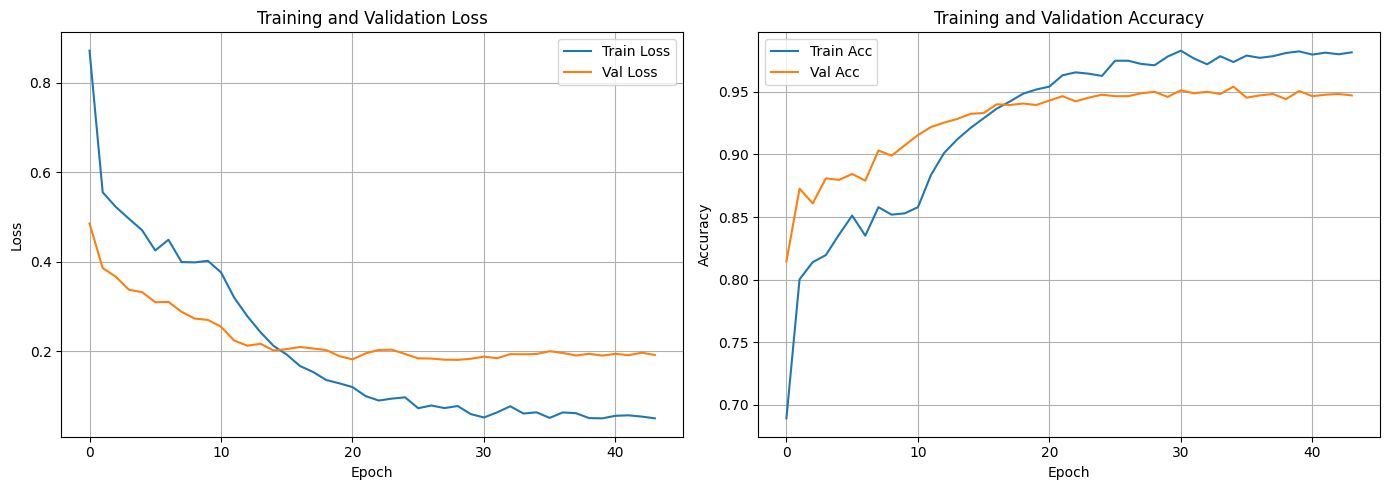


Best model saved as 'best_material_classifier.pth'


In [36]:
# Imports (add to existing imports cell)
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(test_df)}")
print("\nClass distribution in training set:")
display(train_df['label'].value_counts())

# Define transforms
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Custom Dataset class
class MaterialDataset(Dataset):
    """Custom Dataset for material classification"""
    
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
    
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        img_path = self.dataframe.loc[idx, 'file_path']
        label = self.dataframe.loc[idx, 'label']
        
        # Load image
        image = Image.open(img_path).convert('RGB')
        
        # Apply transforms
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Create datasets
train_dataset = MaterialDataset(train_df, transform=train_transforms)
val_dataset = MaterialDataset(test_df, transform=val_transforms)

print(f"\nDataset sizes:")
print(f"Train: {len(train_dataset)}")
print(f"Validation: {len(val_dataset)}")

# Create WeightedRandomSampler for handling class imbalance
class_counts = train_df['label'].value_counts().sort_index()
class_weights = 1.0 / class_counts
sample_weights = train_df['label'].map(class_weights).values

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# Create DataLoaders
BATCH_SIZE = 32
NUM_WORKERS = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"\nDataLoader configuration:")
print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

# Define Model Architecture
class MaterialClassifier(nn.Module):
    """CNN classifier using pretrained ResNet-50 backbone"""
    
    def __init__(self, num_classes=6, freeze_backbone=True):
        super(MaterialClassifier, self).__init__()
        
        # Load pretrained ResNet-50
        self.backbone = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V2)
        
        # Freeze backbone if specified
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
        
        # Replace final FC layer
        num_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)
    
    def unfreeze_backbone(self, num_layers=10):
        """Unfreeze top layers of backbone for fine-tuning"""
        # Get all parameters
        params = list(self.backbone.parameters())
        # Unfreeze last num_layers
        for param in params[-num_layers:]:
            param.requires_grad = True

# Initialize model
model = MaterialClassifier(num_classes=6, freeze_backbone=True)
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nModel Architecture: ResNet-50")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# Define loss function with class weights
class_weights_tensor = torch.FloatTensor([1.0 / count for count in class_counts.values])
class_weights_tensor = class_weights_tensor.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Define optimizer (Adam - "the goat")
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=1e-4
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3
)

# Early stopping configuration
class EarlyStopping:
    """Early stopping to stop training when validation loss doesn't improve"""
    
    def __init__(self, patience=7, min_delta=0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model = None
    
    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model = model.state_dict().copy()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f"EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model = model.state_dict().copy()
            self.counter = 0

early_stopping = EarlyStopping(patience=15, verbose=True)

print("\nTraining configuration:")
print(f"Loss function: CrossEntropyLoss (with class weights)")
print(f"Optimizer: Adam (lr=0.001, weight_decay=1e-4)")
print(f"LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)")
print(f"Early stopping: Enabled (patience=15)")
print("\nReady to train!")

# Training function
def train_epoch(model, loader, criterion, optimizer, device):
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        # Statistics
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc

# Validation function
def validate(model, loader, criterion, device):
    """Validate the model"""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc

# Training loop
NUM_EPOCHS = 100  # "Set epochs to the moon"
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'lr': []
}

print("\n" + "="*50)
print("STARTING TRAINING")
print("="*50)

for epoch in range(NUM_EPOCHS):
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    # Record history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['lr'].append(optimizer.param_groups[0]['lr'])
    
    # Print progress
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"  LR: {optimizer.param_groups[0]['lr']:.6f}")
    
    # Learning rate scheduling
    scheduler.step(val_loss)
    
    # Early stopping
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print("\nEarly stopping triggered!")
        model.load_state_dict(early_stopping.best_model)
        break
    
    # Unfreeze backbone after 10 epochs for fine-tuning
    if epoch == 10:
        print("\n" + "="*50)
        print("UNFREEZING BACKBONE FOR FINE-TUNING")
        print("="*50)
        model.unfreeze_backbone(num_layers=20)
        optimizer = optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=0.0001,  # Lower learning rate for fine-tuning
            weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='min',
            factor=0.5,
            patience=3
        )

print("\n" + "="*50)
print("TRAINING COMPLETE")
print("="*50)

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(history['train_acc'], label='Train Acc')
axes[1].plot(history['val_acc'], label='Val Acc')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Save the best model
torch.save(model.state_dict(), 'best_material_classifier.pth')
print("\nBest model saved as 'best_material_classifier.pth'")

## Evaluation <a id='evaluation'></a>

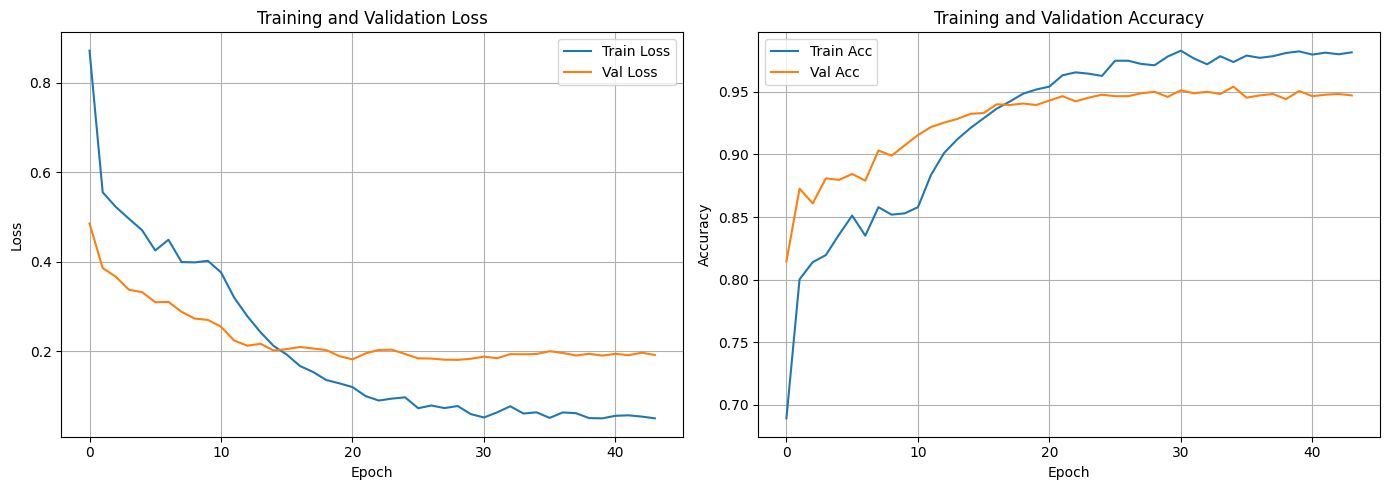


Best model saved as 'best_material_classifier_95.42.pth'
Best Validation Accuracy: 95.42%


In [37]:
# Evaluation - plotting training history and saving model
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Loss plot
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)
# Accuracy plot
axes[1].plot(history['train_acc'], label='Train Acc')
axes[1].plot(history['val_acc'], label='Val Acc')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

# Calculate best validation accuracy and save model with accuracy in filename
best_val_acc = max(history['val_acc'])
best_val_acc_pct = best_val_acc * 100
model_filename = f'best_material_classifier_{best_val_acc_pct:.2f}.pth'

torch.save(model.state_dict(), model_filename)
print(f"\n{'='*50}")
print(f"Best model saved as '{model_filename}'")
print(f"Best Validation Accuracy: {best_val_acc_pct:.2f}%")
print(f"{'='*50}")


## Conclusion <a id='conclusion'></a>
_Add some profound detail about the result of this excercise_

_Things that could have been done better:_

- ...

---

## Appendix
- **Author:** Morrison Page
- **Date:** 14/12/2025
- **Environment:** `Kernal - Python 3.12.3`
